# Final Fine-Tuned Model: DistilGPT-2 for Police Field-Report Narratives
Author: Navi Dharshan B (1716785)

One carefully configured fine-tune of **DistilGPT-2** on redacted Boston Police FIO narratives, with **early
stopping** to prevent overfitting, followed by a full evaluation on a held-out **test set** against the base model.
The saved model is the one deployed in the Streamlit app.

**Configuration choices, informed by an earlier hyperparameter study** (`FIO_Narrative_LM_Finetuning.ipynb`):

| Setting | Study reference | Final model | Reason |
|---|---|---|---|
| Training data | 540 narratives | **≈3,700 narratives** (80% of all) | the study overfit after epoch 2 – more data is the strongest cure |
| Validation / test | 60 / – | **≈460 / ≈460** narratives | early stopping uses validation; metrics are reported on unseen test data |
| Learning rate | 5e-4 | **1e-4** with 10% warm-up, linear decay | 5e-4 overfit fast and 5e-6 underfit; 1e-4 is a standard GPT-2 fine-tuning rate between them |
| Weight decay | 0 | **0.01** | mild regularisation |
| Batch size | 4 | **8** | smoother updates (batch 16 overfit least in the study) |
| Epochs | 5 fixed | **up to 10, early stopping** (patience 3 evaluations) | training stops when validation loss stops improving |
| Checkpoint kept | last epoch | **best validation loss** | the deployed weights are the least-overfit ones |

**Runtime:** T4 GPU → Run all, about 15–20 minutes.

## 0. Setup

In [1]:
import os, re, math, time, random, json, shutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, TrainerCallback,
                          EarlyStoppingCallback, set_seed)
from transformers.trainer_callback import PrinterCallback
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU – switch to a T4 GPU runtime")
OUT = "final_outputs"; os.makedirs(OUT, exist_ok=True)
pd.set_option("display.max_colwidth", 220)

Device: Tesla T4


## 1. Data
Boston Police Department FIO records 2024 (`2024_annual_fio.csv`, Analyze Boston, PDDL licence) – the narrative
field `contact_reason`. Upload the CSV when asked (Analyze Boston blocks automated downloads from Colab).

In [2]:
CSV = "2024_annual_fio.csv"
if not os.path.exists(CSV):
    try:
        import urllib.request
        url = ("https://data.boston.gov/dataset/4ebae674-28c1-4b9b-adc3-c04c99234a68/resource/"
               "060526ca-ab4e-4da5-997c-1a4460bde5fd/download/2024_annual_fio.csv")
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r, open(CSV, "wb") as fh:
            fh.write(r.read())
    except Exception as e:
        print("Download failed:", e, "– please upload 2024_annual_fio.csv")
        from google.colab import files
        files.upload()
raw = pd.read_csv(CSV, encoding="utf-8-sig")
print("Records:", len(raw))

Download failed: HTTP Error 403: Forbidden – please upload 2024_annual_fio.csv


Saving 2024_annual_fio.csv to 2024_annual_fio.csv
Records: 4860


### 1.1 Cleaning and privacy redaction
Same rules as the study: drop empty and duplicate narratives, replace the publisher's `XXX` masks with
`[REDACTED]`, and replace officer names (from the record's own columns), street addresses, Boston neighbourhoods and
phone numbers with placeholders. Narratives under 15 words are dropped.

In [3]:
TEXT = "contact_reason"
df = raw[[TEXT]].copy()
df[TEXT] = df[TEXT].fillna("").astype(str)
df = df[df[TEXT].str.strip() != ""].drop_duplicates(subset=TEXT)

name_words = set()
for col in ["contact_officer_name", "supervisor_name"]:
    for v in raw[col].dropna().astype(str):
        for w in re.split(r"[,\s]+", v):
            w = w.strip(".").lower()
            if len(w) > 2:
                name_words.add(w)
vocab = pd.Series(re.findall(r"\b[a-z][a-z'\-]+\b", " ".join(df[TEXT]))).value_counts()
officer_words = {w for w in name_words if vocab.get(w, 0) < 3}

STREET = "St|Street|Ave|Avenue|Rd|Road|Blvd|Pl|Place|Sq|Square|Ter|Terrace|Way|Ct|Court|Dr|Drive|Pk|Park|Hwy"
HOODS = ("Allston|Brighton|Back Bay|Bay Village|Beacon Hill|Charlestown|Chinatown|Dorchester|Downtown|East Boston|"
         "Fenway|Hyde Park|Jamaica Plain|Mattapan|Mission Hill|North End|Roslindale|Roxbury|South Boston|South End|"
         "West End|West Roxbury|Leather District|Longwood")
MASK = re.compile(r"X{2,}(?:\s*[/\-]\s*X{2,})*")
RULES = [(re.compile(rf"\b(?:\d{{1,5}}\s+)?(?:[A-Z][a-z]+\s){{1,3}}(?:{STREET})\b\.?"), "[ADDRESS]"),
         (re.compile(rf"\b(?:{HOODS})\b", re.I), "[PLACE]"),
         (re.compile(r"\b\(?\d{3}\)?[-. ]?\d{3}[-. ]\d{4}\b"), "[PHONE]")]
CAP = re.compile(r"\b[A-Z][A-Za-z'\-]+\b")

def clean(t):
    t = MASK.sub(" [REDACTED] ", t)
    t = CAP.sub(lambda m: "[PERSON]" if m.group(0).lower() in officer_words else m.group(0), t)
    for rx, tag in RULES:
        t = rx.sub(tag, t)
    t = re.sub(r"(?:\[REDACTED\]\s*){2,}", "[REDACTED] ", t)
    return re.sub(r"\s+", " ", t).strip()

df["text"] = df[TEXT].map(clean)
df = df[df.text.str.split().str.len() >= 15].reset_index(drop=True)
print("Usable narratives:", len(df))

Usable narratives: 4603


### 1.2 Train / validation / test split (80 / 10 / 10)
* **train** – used to update the weights
* **validation** – checked during training; drives early stopping and picks the best checkpoint
* **test** – never seen during training; all final metrics are computed on it

In [4]:
shuffled = df.text.sample(frac=1, random_state=SEED).tolist()
n = len(shuffled); n_val = n_test = int(0.10 * n)
test_texts, val_texts, train_texts = shuffled[:n_test], shuffled[n_test:n_test + n_val], shuffled[n_test + n_val:]

MODEL_NAME = "distilgpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

def count_tokens(texts):
    return sum(len(tokenizer(t)["input_ids"]) + 1 for t in texts)

display(pd.DataFrame({"narratives": [len(train_texts), len(val_texts), len(test_texts)],
                      "GPT-2 tokens": [count_tokens(train_texts), count_tokens(val_texts), count_tokens(test_texts)]},
                     index=["train", "validation", "test"]))

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

,narratives,GPT-2 tokens
train,3683,635327
validation,460,81258
test,460,76335


### 1.3 Fixed-length token blocks
Narratives are tokenised, joined with GPT-2's end-of-text token (so the model learns where a report ends) and cut
into 128-token blocks. Labels equal the inputs; the model shifts them internally to predict each next token.

In [5]:
BLOCK = 128

class BlockDataset(Dataset):
    def __init__(self, texts, block_size=BLOCK):
        ids = []
        for t in texts:
            ids.extend(tokenizer(t)["input_ids"] + [tokenizer.eos_token_id])
        n_blocks = len(ids) // block_size
        self.blocks = torch.tensor(ids[: n_blocks * block_size], dtype=torch.long).view(n_blocks, block_size)
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, i):
        x = self.blocks[i]
        return {"input_ids": x, "attention_mask": torch.ones_like(x), "labels": x.clone()}

train_ds, val_ds, test_ds = BlockDataset(train_texts), BlockDataset(val_texts), BlockDataset(test_texts)
print(f"Blocks – train {len(train_ds)}, validation {len(val_ds)}, test {len(test_ds)}")

Blocks – train 4963, validation 634, test 596


## 2. Fine-tuning with early stopping
* Validation loss is computed every `EVAL_STEPS` steps (≈ 4 times per epoch) and a checkpoint is saved each time.
* `EarlyStoppingCallback(patience=3)` stops training when validation loss has not improved for 3 evaluations in a
  row (minimum improvement 0.005).
* `load_best_model_at_end=True` restores the checkpoint with the **lowest validation loss**, so the final model is
  taken from before any overfitting begins.

In [6]:
LR, EPOCHS, BATCH, WARMUP, WD = 1e-4, 10, 8, 0.10, 0.01
steps_per_epoch = math.ceil(len(train_ds) / BATCH)
EVAL_STEPS = max(25, steps_per_epoch // 4)
WARMUP_STEPS = int(WARMUP * steps_per_epoch * EPOCHS)

class LossLogger(TrainerCallback):
    def __init__(self):
        self.train, self.eval = [], []
    def on_log(self, args, state, control, logs=None, **kwargs):
        logs = logs or {}
        if "loss" in logs:
            self.train.append({"step": state.global_step, "epoch": logs.get("epoch"), "loss": logs["loss"],
                               "lr": logs.get("learning_rate")})
        if "eval_loss" in logs:
            self.eval.append({"step": state.global_step, "epoch": logs.get("epoch"), "loss": logs["eval_loss"]})

common = dict(output_dir=f"{OUT}/checkpoints", learning_rate=LR, num_train_epochs=EPOCHS,
              per_device_train_batch_size=BATCH, per_device_eval_batch_size=16,
              warmup_steps=WARMUP_STEPS, weight_decay=WD, lr_scheduler_type="linear",
              logging_strategy="steps", logging_steps=10,
              save_strategy="steps", save_steps=EVAL_STEPS, eval_steps=EVAL_STEPS, save_total_limit=2,
              load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
              fp16=(device == "cuda"), seed=SEED, data_seed=SEED, report_to="none", disable_tqdm=True)
try:
    args = TrainingArguments(eval_strategy="steps", **common)
except TypeError:
    args = TrainingArguments(evaluation_strategy="steps", **common)

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
logger = LossLogger()
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  callbacks=[logger, EarlyStoppingCallback(early_stopping_patience=3, early_stopping_threshold=0.005)])
trainer.remove_callback(PrinterCallback)

print(f"lr {LR}, batch {BATCH}, up to {EPOCHS} epochs = {steps_per_epoch * EPOCHS} steps; "
      f"evaluating every {EVAL_STEPS} steps")
t0 = time.time()
trainer.train()
minutes = (time.time() - t0) / 60

ev = pd.DataFrame(logger.eval)
best_row = ev.loc[ev.loss.idxmin()]
stopped_epoch = ev.epoch.iloc[-1]
print(f"Stopped after {stopped_epoch:.2f} epochs ({trainer.state.global_step} steps, {minutes:.1f} min).")
print(f"Best validation loss {best_row.loss:.3f} at step {int(best_row.step)} (epoch {best_row.epoch:.2f}) "
      f"– this checkpoint is restored: {trainer.state.best_model_checkpoint}")
model = trainer.model.eval()

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

lr 0.0001, batch 8, up to 10 epochs = 6210 steps; evaluating every 155 steps


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Stopped after 4.74 epochs (2945 steps, 11.0 min).
Best validation loss 2.276 at step 2480 (epoch 3.99) – this checkpoint is restored: final_outputs/checkpoints/checkpoint-2480


### 2.1 Training and validation curves, learning-rate schedule

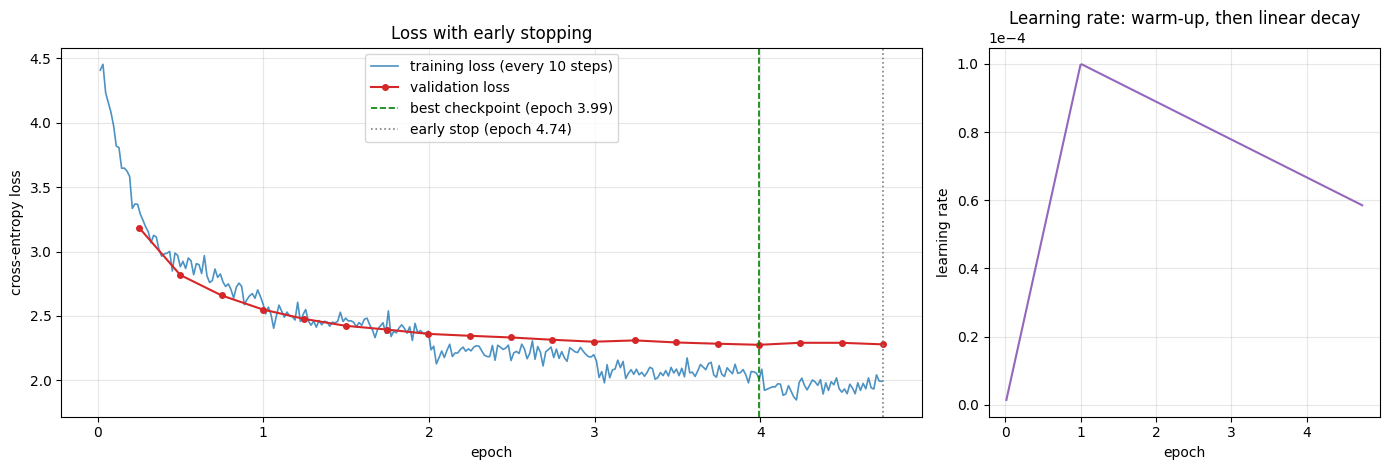

In [7]:
tr = pd.DataFrame(logger.train)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax.plot(tr.epoch, tr.loss, color="#1f77b4", lw=1.2, alpha=0.8, label="training loss (every 10 steps)")
ax.plot(ev.epoch, ev.loss, "o-", color="#d62728", ms=4, label="validation loss")
ax.axvline(best_row.epoch, color="green", ls="--", lw=1.2, label=f"best checkpoint (epoch {best_row.epoch:.2f})")
ax.axvline(stopped_epoch, color="grey", ls=":", lw=1.2, label=f"early stop (epoch {stopped_epoch:.2f})")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.set_title("Loss with early stopping")
ax.legend(); ax.grid(alpha=0.3)
ax2.plot(tr.epoch, tr.lr, color="#9467bd")
ax2.set_xlabel("epoch"); ax2.set_ylabel("learning rate"); ax2.set_title("Learning rate: warm-up, then linear decay")
ax2.ticklabel_format(axis="y", style="sci", scilimits=(0, 0)); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/final_training_curves.png", dpi=150); plt.show()
tr.to_csv(f"{OUT}/training_log.csv", index=False); ev.to_csv(f"{OUT}/validation_log.csv", index=False)

## 3. Evaluation on the held-out test set
Every metric is computed for the **base DistilGPT-2** and the **fine-tuned model** on exactly the same test data.

### 3.1 Loss, perplexity and next-token accuracy
* **Loss / perplexity** – how well the model predicts real unseen narratives (perplexity = e^loss; lower is better).
* **Next-token accuracy** – for every position in the test text, is the model's top guess (top-1) or one of its
  five top guesses (top-5) the real next token? This is the language-model form of accuracy.

In [8]:
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device).eval()
model.to(device)

@torch.no_grad()
def lm_metrics(m, dataset, bs=16):
    tot_loss = tot_tok = top1 = top5 = 0
    for i in range(0, len(dataset), bs):
        x = torch.stack([dataset[j]["input_ids"] for j in range(i, min(i + bs, len(dataset)))]).to(device)
        logits = m(input_ids=x).logits[:, :-1].float()
        target = x[:, 1:]
        loss = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)), target.reshape(-1),
                                                 reduction="sum")
        k5 = logits.topk(5, dim=-1).indices
        top1 += (k5[..., 0] == target).sum().item()
        top5 += (k5 == target.unsqueeze(-1)).any(-1).sum().item()
        tot_loss += loss.item(); tot_tok += target.numel()
    l = tot_loss / tot_tok
    return {"loss": l, "perplexity": math.exp(l), "next-token accuracy (top-1)": top1 / tot_tok,
            "next-token accuracy (top-5)": top5 / tot_tok}

lm_table = pd.DataFrame({"base DistilGPT-2": lm_metrics(base_model, test_ds),
                         "fine-tuned": lm_metrics(model, test_ds)}).T
train_fit = lm_metrics(model, BlockDataset(train_texts[:len(test_texts)]))      # same-size train sample
display(lm_table.style.format({"loss": "{:.3f}", "perplexity": "{:.1f}",
                               "next-token accuracy (top-1)": "{:.1%}", "next-token accuracy (top-5)": "{:.1%}"}))
gap = lm_table.loc["fine-tuned", "loss"] - train_fit["loss"]
print(f"Overfitting check – fine-tuned loss on training text {train_fit['loss']:.3f} vs test {lm_table.loc['fine-tuned', 'loss']:.3f} "
      f"(gap {gap:+.3f}; a small gap means the model generalises rather than memorises)")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

,loss,perplexity,next-token accuracy (top-1),next-token accuracy (top-5)
base DistilGPT-2,4.365,78.6,30.9%,48.6%
fine-tuned,2.304,10.0,52.9%,74.7%


Overfitting check – fine-tuned loss on training text 1.866 vs test 2.304 (gap +0.438; a small gap means the model generalises rather than memorises)


### 3.2 Completion quality – ROUGE-L, BLEU, diversity and style
For each of 150 test narratives, both models receive the **first 15 words** and write a continuation (greedy
decoding with a repetition penalty, so results are deterministic). The continuation is compared with the **real
rest of the narrative**:
* **ROUGE-L precision / recall / F1** – longest common word subsequence with the real text (F1 balances how much of
  the output is correct and how much of the real text is recovered);
* **BLEU-4** – overlap of 1- to 4-word sequences with the real text;
* **distinct-1 / distinct-2** – share of unique words / word pairs across all outputs (variety);
* **repetition rate** – share of repeated 3-word sequences inside an output (looping);
* **domain-style rate** – share of outputs using FIO conventions ([REDACTED], [ADDRESS], VAL, CJIS, FIO, DOB, MA REG…);
* **ends naturally** – share of outputs where the model emitted the end-of-text token on its own.

In [9]:
def words(t):
    return re.findall(r"\[[A-Z]+\]|[a-z0-9']+", t.lower())

def lcs(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b, 1):
            cur.append(prev[j - 1] + 1 if x == y else max(prev[j], cur[-1]))
        prev = cur
    return prev[-1]

def rouge_l(gen, ref):
    g, r = words(gen), words(ref)
    if not g or not r:
        return 0.0, 0.0, 0.0
    l = lcs(g, r); p, rc = l / len(g), l / len(r)
    return p, rc, (2 * p * rc / (p + rc) if p + rc else 0.0)

def bleu4(gens, refs):
    """Corpus BLEU-4 with add-one smoothing and brevity penalty."""
    match = [0] * 4; total = [0] * 4; gl = rl = 0
    for g, r in zip(gens, refs):
        g, r = words(g), words(r); gl += len(g); rl += len(r)
        for n in range(1, 5):
            gc = Counter(tuple(g[i:i + n]) for i in range(len(g) - n + 1))
            rc = Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1))
            match[n - 1] += sum(min(c, rc[k]) for k, c in gc.items()); total[n - 1] += sum(gc.values())
    if gl == 0:
        return 0.0
    logp = sum(math.log((m + 1) / (t + 1)) for m, t in zip(match, total)) / 4
    bp = 1.0 if gl > rl else math.exp(1 - rl / gl)
    return bp * math.exp(logp)

def distinct(texts, n):
    grams = [tuple(w[i:i + n]) for t in texts for w in [words(t)] for i in range(len(w) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

def repetition(t):
    w = words(t); tri = [tuple(w[i:i + 3]) for i in range(len(w) - 2)]
    return 1 - len(set(tri)) / len(tri) if tri else 0.0

STYLE = re.compile(r"\[(?:REDACTED|ADDRESS|PERSON|PLACE)\]|\bVALs?\b|\bCJIS\b|\bFIO|\bDOB\b|\bMA REG|\bF/A\b|\bM/V\b|\bpat frisk",
                   re.I)

In [10]:
N_EVAL, PROMPT_WORDS, MAX_REF = 150, 15, 60
eval_items = []
for t in test_texts:
    w = t.split()
    if len(w) >= PROMPT_WORDS + 10:
        eval_items.append((" ".join(w[:PROMPT_WORDS]), " ".join(w[PROMPT_WORDS:PROMPT_WORDS + MAX_REF])))
    if len(eval_items) == N_EVAL:
        break

@torch.no_grad()
def complete(m, prompt):
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    out = m.generate(**enc, max_new_tokens=80, do_sample=False, repetition_penalty=1.2, no_repeat_ngram_size=3,
                     pad_token_id=tokenizer.eos_token_id)
    new = out[0][enc["input_ids"].shape[1]:]
    ended = bool((new == tokenizer.eos_token_id).any())
    text = tokenizer.decode(new, skip_special_tokens=True)
    return " ".join(text.split()[:MAX_REF]), ended

t0 = time.time()
gen_rows = []
for name, m in [("base DistilGPT-2", base_model), ("fine-tuned", model)]:
    for prompt, ref in eval_items:
        g, ended = complete(m, prompt)
        p, r, f = rouge_l(g, ref)
        gen_rows.append({"model": name, "prompt": prompt, "reference": ref, "generated": g, "ended": ended,
                         "rouge_p": p, "rouge_r": r, "rouge_f": f, "repetition": repetition(g),
                         "style": bool(STYLE.search(g))})
gen_df = pd.DataFrame(gen_rows)
print(f"Generated {len(gen_df)} completions in {(time.time() - t0) / 60:.1f} min")

comp = {}
for name, g in gen_df.groupby("model", sort=False):
    comp[name] = {"ROUGE-L precision": g.rouge_p.mean(), "ROUGE-L recall": g.rouge_r.mean(),
                  "ROUGE-L F1": g.rouge_f.mean(), "BLEU-4": bleu4(g.generated, g.reference),
                  "distinct-1": distinct(g.generated, 1), "distinct-2": distinct(g.generated, 2),
                  "repetition rate": g.repetition.mean(), "domain-style rate": g["style"].mean(),
                  "ends naturally": g.ended.mean(), "avg words": g.generated.str.split().str.len().mean()}
real_style = np.mean([bool(STYLE.search(r)) for _, r in eval_items])
comp_table = pd.DataFrame(comp).T
display(comp_table.style.format("{:.3f}").format({"domain-style rate": "{:.0%}", "ends naturally": "{:.0%}",
                                                  "avg words": "{:.1f}"}))
print(f"For reference, {real_style:.0%} of the real continuations show the same domain markers.")
gen_df.to_csv(f"{OUT}/test_completions.csv", index=False)

Generated 300 completions in 2.7 min


,ROUGE-L precision,ROUGE-L recall,ROUGE-L F1,BLEU-4,distinct-1,distinct-2,repetition rate,domain-style rate,ends naturally,avg words
base DistilGPT-2,0.099461,0.106344,0.099707,0.004015,0.169037,0.597057,0.000000,3%,17%,55.9
fine-tuned,0.192054,0.176681,0.179326,0.037589,0.096417,0.321977,0.003757,99%,49%,48.6


For reference, 97% of the real continuations show the same domain markers.


### 3.3 Example completions on unseen test narratives

In [11]:
for i in range(3):
    prompt, ref = eval_items[i]
    b = gen_df[(gen_df.model == "base DistilGPT-2") & (gen_df.prompt == prompt)].generated.iloc[0]
    f = gen_df[(gen_df.model == "fine-tuned") & (gen_df.prompt == prompt)].generated.iloc[0]
    print(f"PROMPT    : {prompt}")
    print(f"REAL      : {ref}")
    print(f"BASE      : {b}")
    print(f"FINE-TUNED: {f}\n")
print("Generated text is synthetic and describes no real event.")

PROMPT    : About [REDACTED] :12am on [REDACTED] /17/2024 Officers were in the area of Morton and [ADDRESS]
REAL      : when they observed two males wearing hoodies and "Shiesty" style masks walking up to the window at the Puma gas station. Officers observed one of the males holding his waist as he was walking towards the window. As officers drove by the individuals one of the males made eye contact with officers and alerted the other individuals of the officers
BASE      : at about 3:30pm. The officers arrived to investigate a disturbance, but they found no evidence that there was any violence or disorder within their jurisdiction (except for one incident involving an officer). The police did not respond immediately after this report had been made public by local media outlets.[1][2]. Police have since confirmed it is possible that some members may
FINE-TUNED: when they observed a male matching the description walking down [PERSON] Street towards [ADVERTISING] Officer stopped the indi

## 4. Summary of the final model

In [12]:
ft, base = lm_table.loc["fine-tuned"], lm_table.loc["base DistilGPT-2"]
cf, cb = comp_table.loc["fine-tuned"], comp_table.loc["base DistilGPT-2"]
summary = pd.DataFrame([
    ("Test perplexity (lower = better)", base["perplexity"], ft["perplexity"]),
    ("Next-token accuracy, top-1", base["next-token accuracy (top-1)"], ft["next-token accuracy (top-1)"]),
    ("Next-token accuracy, top-5", base["next-token accuracy (top-5)"], ft["next-token accuracy (top-5)"]),
    ("ROUGE-L F1", cb["ROUGE-L F1"], cf["ROUGE-L F1"]),
    ("ROUGE-L precision", cb["ROUGE-L precision"], cf["ROUGE-L precision"]),
    ("ROUGE-L recall", cb["ROUGE-L recall"], cf["ROUGE-L recall"]),
    ("BLEU-4", cb["BLEU-4"], cf["BLEU-4"]),
    ("Domain-style rate", cb["domain-style rate"], cf["domain-style rate"]),
    ("Repetition rate (lower = better)", cb["repetition rate"], cf["repetition rate"]),
    ("Distinct-2 (variety)", cb["distinct-2"], cf["distinct-2"]),
], columns=["metric", "base DistilGPT-2", "fine-tuned"]).set_index("metric")
summary["change"] = summary["fine-tuned"] - summary["base DistilGPT-2"]
display(summary.style.format("{:.3f}"))
summary.to_csv(f"{OUT}/final_metrics.csv")
print(f"Training: lr {LR}, batch {BATCH}, warm-up {WARMUP:.0%}, weight decay {WD}; early stopping after "
      f"{stopped_epoch:.2f} of {EPOCHS} epochs; best checkpoint at epoch {best_row.epoch:.2f} "
      f"(validation loss {best_row.loss:.3f}); train/test loss gap {gap:+.3f}.")

,base DistilGPT-2,fine-tuned,change
metric,,,
Test perplexity (lower = better),78.617,10.016,-68.601
"Next-token accuracy, top-1",0.309,0.529,0.219
"Next-token accuracy, top-5",0.486,0.747,0.261
ROUGE-L F1,0.100,0.179,0.080
ROUGE-L precision,0.099,0.192,0.093
ROUGE-L recall,0.106,0.177,0.070
BLEU-4,0.004,0.038,0.034
Domain-style rate,0.027,0.987,0.960
Repetition rate (lower = better),0.000,0.004,0.004


Training: lr 0.0001, batch 8, warm-up 10%, weight decay 0.01; early stopping after 4.74 of 10 epochs; best checkpoint at epoch 3.99 (validation loss 2.276); train/test loss gap +0.438.


### 4.1 Performance plots
Saved as PNG files with the model so the deployed app can show them.

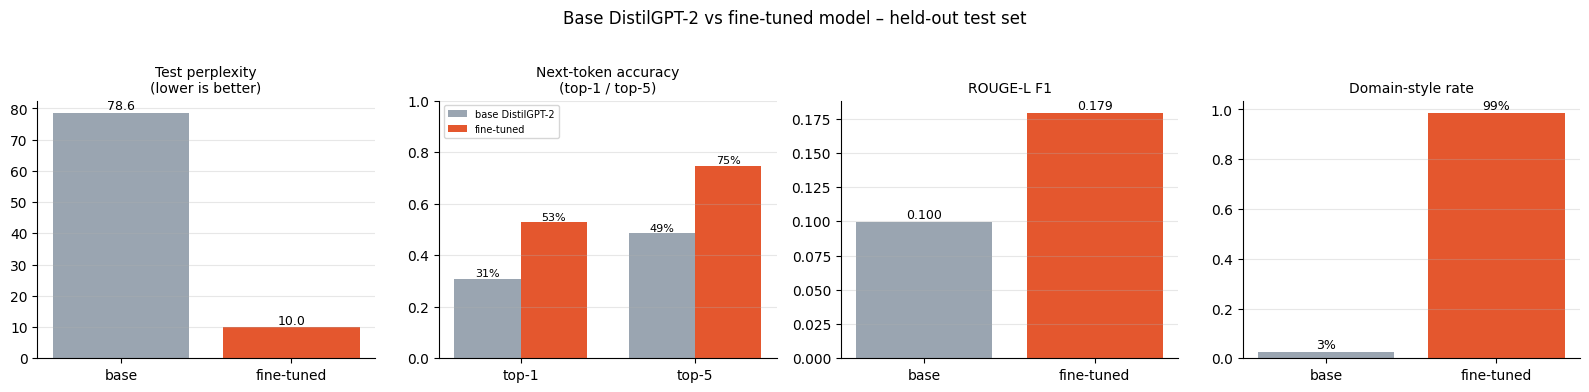

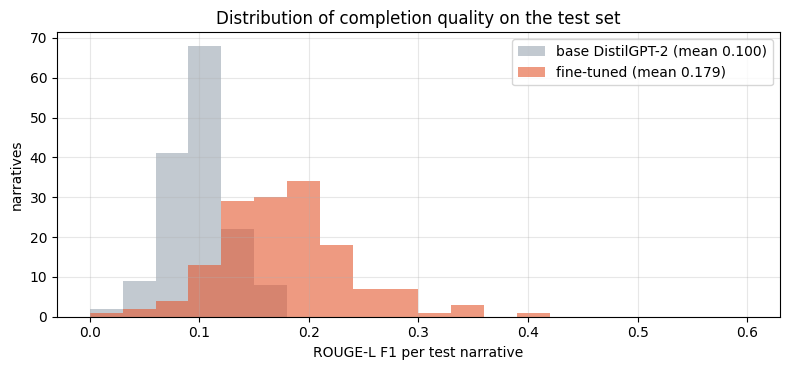

In [13]:
COL = {"base DistilGPT-2": "#9aa5b1", "fine-tuned": "#e4572e"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
panels = [("Test perplexity\n(lower is better)", "perplexity", lm_table, "{:.1f}"),
          ("Next-token accuracy\n(top-1 / top-5)", None, lm_table, "{:.0%}"),
          ("ROUGE-L F1", "ROUGE-L F1", comp_table, "{:.3f}"),
          ("Domain-style rate", "domain-style rate", comp_table, "{:.0%}")]
for ax, (title, col, tbl, fmt) in zip(axes, panels):
    if col is None:
        x = np.arange(2); w = 0.38
        for k, (name, row) in enumerate(lm_table.iterrows()):
            vals = [row["next-token accuracy (top-1)"], row["next-token accuracy (top-5)"]]
            bars = ax.bar(x + (k - 0.5) * w, vals, w, color=COL[name], label=name)
            ax.bar_label(bars, labels=[fmt.format(v) for v in vals], fontsize=8)
        ax.set_xticks(x, ["top-1", "top-5"]); ax.set_ylim(0, 1)
    else:
        vals = tbl[col]
        bars = ax.bar(vals.index, vals.values, color=[COL[i] for i in vals.index])
        ax.bar_label(bars, labels=[fmt.format(v) for v in vals.values], fontsize=9)
        ax.set_xticks(range(len(vals)), ["base", "fine-tuned"])
    ax.set_title(title, fontsize=10); ax.grid(axis="y", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(fontsize=7, loc="upper left")
plt.suptitle("Base DistilGPT-2 vs fine-tuned model – held-out test set", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT}/final_metrics_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
for name, g in gen_df.groupby("model", sort=False):
    ax.hist(g.rouge_f, bins=20, range=(0, 0.6), alpha=0.6, color=COL[name], label=f"{name} (mean {g.rouge_f.mean():.3f})")
ax.set_xlabel("ROUGE-L F1 per test narrative"); ax.set_ylabel("narratives"); ax.legend()
ax.set_title("Distribution of completion quality on the test set"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/rouge_distribution.png", dpi=150); plt.show()
lm_table.to_csv(f"{OUT}/test_lm_metrics.csv"); comp_table.to_csv(f"{OUT}/test_completion_metrics.csv")

## 5. Save the model for future use and for the web app
The saved folder `fio_lm_model/` contains everything needed to reuse or deploy the model:

| Content | Files |
|---|---|
| Model weights and configuration | `model.safetensors`, `config.json`, `generation_config.json` |
| Tokenizer | `tokenizer.json`, `tokenizer_config.json`, `vocab.json`, `merges.txt`, … |
| Training settings and all test metrics | `training_info.json` |
| Model card | `README.md` |
| Every plot and results table | `results/` |

It is then stored in three places:
1. **Google Drive** – `MyDrive/FIO_LM/final_model_<date-time>/` (permanent copy; nothing is overwritten).
2. **Hugging Face Hub** – pushed to the repository the Streamlit app loads, **replacing the deployed model**.
3. **Your computer** – `fio_lm_model.zip` download as a backup.

In [14]:
SAVE_DIR = "fio_lm_model"
if os.path.exists(SAVE_DIR):
    shutil.rmtree(SAVE_DIR)
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

val_base = lm_metrics(base_model, val_ds)["loss"]
info = {"base_model": MODEL_NAME, "run": "final (early stopping)",
        "trained_on": time.strftime("%Y-%m-%d %H:%M"),
        "config": {"lr": LR, "batch_size": BATCH, "max_epochs": EPOCHS, "warmup_ratio": WARMUP,
                   "warmup_steps": WARMUP_STEPS, "weight_decay": WD, "block_size": BLOCK,
                   "early_stopping_patience": 3, "early_stopping_threshold": 0.005, "eval_steps": EVAL_STEPS},
        "stopped_epoch": float(stopped_epoch), "best_epoch": float(best_row.epoch),
        "best_step": int(best_row.step), "final_val_loss": float(best_row.loss), "base_val_loss": float(val_base),
        "train_test_loss_gap": float(gap),
        "test": {"base": {**{k: float(v) for k, v in base.items()}, **{k: float(v) for k, v in cb.items()}},
                 "fine_tuned": {**{k: float(v) for k, v in ft.items()}, **{k: float(v) for k, v in cf.items()}}},
        "corpus": f"{len(train_texts)} train / {len(val_texts)} validation / {len(test_texts)} test redacted "
                  "Boston FIO narratives (2024)"}
json.dump(info, open(f"{SAVE_DIR}/training_info.json", "w"), indent=1)

# every plot and results table travels with the model
shutil.rmtree(f"{OUT}/checkpoints", ignore_errors=True)
shutil.copytree(OUT, f"{SAVE_DIR}/results", dirs_exist_ok=True)

# model card shown on the Hugging Face page
rows = "\n".join(f"| {m} | {r['base DistilGPT-2']:.3f} | {r['fine-tuned']:.3f} |" for m, r in summary.iterrows())
card = f"""---
language: en
license: apache-2.0
base_model: distilgpt2
tags: [text-generation, gpt2, police-reports, fine-tuned]
---
# DistilGPT-2 fine-tuned on Boston Police FIO narratives

MAAI 902 project – Navi Dharshan B. Fine-tuned on {info['corpus']}
(Analyze Boston, PDDL licence; names, officer names, addresses and neighbourhoods replaced with placeholders).

**Training:** learning rate {LR} with {WARMUP:.0%} warm-up and linear decay, batch {BATCH}, weight decay {WD},
block size {BLOCK}; early stopping on validation loss (patience 3) stopped at epoch {stopped_epoch:.2f};
best checkpoint at epoch {best_row.epoch:.2f} (validation loss {best_row.loss:.3f}).

**Held-out test set**

| Metric | Base DistilGPT-2 | Fine-tuned |
|---|---|---|
{rows}

All generated text is synthetic, describes no real event and must not be presented as a police record.
"""
open(f"{SAVE_DIR}/README.md", "w").write(card)
print("Saved:", sorted(os.listdir(SAVE_DIR)))
print("Results:", sorted(os.listdir(f"{SAVE_DIR}/results")))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: ['README.md', 'config.json', 'generation_config.json', 'model.safetensors', 'results', 'tokenizer.json', 'tokenizer_config.json', 'training_info.json']
Results: ['final_metrics.csv', 'final_metrics_comparison.png', 'final_training_curves.png', 'rouge_distribution.png', 'test_completion_metrics.csv', 'test_completions.csv', 'test_lm_metrics.csv', 'training_log.csv', 'validation_log.csv']


### 5.1 Permanent copy in Google Drive

In [15]:
SAVE_TO_DRIVE = True
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        stamp = time.strftime("%Y%m%d_%H%M")
        dest = f"/content/drive/MyDrive/FIO_LM/final_model_{stamp}"
        shutil.copytree(SAVE_DIR, dest)
        print("Saved to Google Drive:", dest)
    except Exception as e:
        print("Drive copy skipped:", e)

Mounted at /content/drive
Saved to Google Drive: /content/drive/MyDrive/FIO_LM/final_model_20261024_1907


### 5.2 Replace the deployed model on Hugging Face
This pushes the folder to the Hugging Face repository the Streamlit app loads (`HF_REPO`), replacing the model and
its results there.

**One-time setup:** create a Hugging Face access token with **Write** permission (huggingface.co → profile →
Settings → Access Tokens). In Colab, click the **key icon** in the left sidebar → **Add new secret**, name it
`HF_TOKEN`, paste the token, and switch **Notebook access** on. If no secret is found, the cell asks for the token
in a hidden input box – never paste it into a visible cell.

In [16]:
PUSH_TO_HUB = True
HF_REPO = "dharshan3119/fio-narrative-distilgpt2"

if PUSH_TO_HUB:
    from huggingface_hub import HfApi
    token = None
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
    except Exception:
        pass
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face write token (input hidden): ")
    api = HfApi(token=token)
    api.create_repo(HF_REPO, repo_type="model", exist_ok=True)
    commit = api.upload_folder(repo_id=HF_REPO, folder_path=SAVE_DIR, repo_type="model",
                               commit_message=f"Final model with early stopping ({info['trained_on']})")
    print("Pushed to", f"https://huggingface.co/{HF_REPO}")
    print("Now reboot the Streamlit app (Manage app → ⋮ → Reboot app) to load the new model.")

Pushed to https://huggingface.co/dharshan3119/fio-narrative-distilgpt2
Now reboot the Streamlit app (Manage app → ⋮ → Reboot app) to load the new model.


### 5.3 Backup downloads

In [17]:
shutil.make_archive("fio_lm_model", "zip", SAVE_DIR)
shutil.make_archive("final_results", "zip", f"{SAVE_DIR}/results")
print("Created fio_lm_model.zip and final_results.zip")
try:
    from google.colab import files
    files.download("fio_lm_model.zip"); files.download("final_results.zip")
except Exception:
    pass

Created fio_lm_model.zip and final_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5.4 Reusing the saved model later
```python
from transformers import AutoTokenizer, AutoModelForCausalLM
repo = "dharshan3119/fio-narrative-distilgpt2"          # or the Google Drive folder path
tok = AutoTokenizer.from_pretrained(repo)
model = AutoModelForCausalLM.from_pretrained(repo)
```

## 6. Notes on the metrics
* **Accuracy and F1 for a generator.** There is no single correct label per input, so classification accuracy and F1
  do not apply directly. Next-token accuracy is the language-model equivalent of accuracy, and ROUGE-L F1 is an F1
  score over the words of the real continuation.
* **Why ROUGE and BLEU stay low.** A narrative can continue in many valid ways; even a perfect model would not
  reproduce the officer's exact words. These scores are useful for *comparing* the two models on the same prompts,
  not as absolute grades.
* **Responsible use.** All generated text is synthetic, must not be presented as a real police record, and may
  reproduce demographic descriptors present in the source reports.